In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

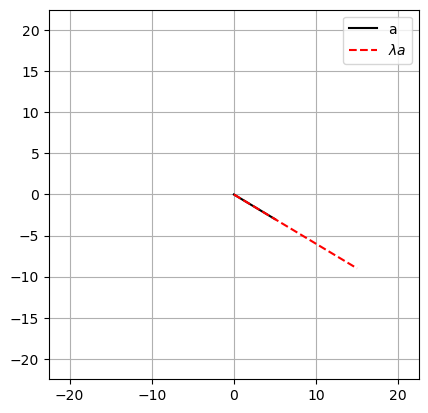

In [5]:
# vector and scalar
a = np.array([5,-3])
sc = 3
a_sc = a*sc

# plot them
plt.plot([0, a[0]], [0, a[1]], "k", label = "a")
plt.plot([0, a_sc[0]], [0, a_sc[1]], "r--", label = "$\lambda a$")

plt.legend()
plt.axis("square")
axlim = max([max(abs(a)), max(abs(a_sc))])*1.5
plt.axis((-axlim,axlim,-axlim,axlim))
plt.grid()
plt.show()


Previously, I mentioned that the data type of a variable storing a vector can sometimes be significant and
sometimes not. Vector-scalar multiplication is a case where the data type is crucial. Let us take the
following example:

In [6]:
scal = 2
v = [3,4,5] #list

w = np.array(v) #np array

print(v*scal)
print(w*scal)

[3, 4, 5, 3, 4, 5]
[ 6  8 10]


The code first creates a scalar (scal) and a vector as a list (v), then converts that list into a NumPy array (w). 

In Python, the asterisk (*) has overloaded functionality; its behavior changes based on the variable type. 

When used with a scalar and a list, it repeats the list 'scal' times, not performing the standard scalar-vector multiplication.

However, with a NumPy array, the asterisk performs elementwise multiplication. 

Pay attention to these differences in real-world coding, as both list repetition and vector-scalar multiplication are common practices.



# Important note about Scalar-Vector Addition
Adding a scalar to a vector isn’t defined in linear algebra because they’re fundamentally different kinds of objects. A scalar is a
single number, while a vector is an ordered set of numbers. In linear algebra, you can add scalars to scalars and vectors to vectors
of the same size, but combining a single number with a set of numbers isn’t a valid operation. However, numerical processing
programs like Python allow for scalar addition to vectors. This operation resembles scalar-vector multiplication, as the scalar is
added to each element of the vector. The following code demonstrates this concept:


# Vector Broadcasting in Python
Broadcasting is a concept unique to modern computer-based linear algebra and isn’t typically covered in traditional textbooks. It
involves repeating an operation between one vector and each element of another vector multiple times

In [9]:
#1. Column Vector + Row Vector
#When you add a (3, 1) column to a (1, 2) row, NumPy expands both to a (3, 2) grid

a = np.array([[10,20,30]]).T #col
b = np.array([1,2]) # row

r=a+b
print(r)

[[11 12]
 [21 22]
 [31 32]]


In [10]:
#2. Row Vector + Column Vector

a = np.array([[10,20,30]]) #row
b = np.array([[1,2]]).T #col

r=a+b
print(r)

[[11 21 31]
 [12 22 32]]


In [13]:
#2. Row Vector + 1D Array

a = np.array([1,2,3])
print(a.shape)

b = np.array([[5],[10],[15]])
print(b.shape)

r=a+b
print(r)
print(r.shape)

(3,)
(3, 1)
[[ 6  7  8]
 [11 12 13]
 [16 17 18]]
(3, 3)


In [14]:
#2. Rule Enforcement (Error Condition)

try:
    np.array([[1,2,3]]) + np.array([1,2])
except ValueError as e:
    print(f"Error:{e}")

Error:operands could not be broadcast together with shapes (1,3) (2,) 


# The Rule for Same-Orientation Vectors
1. Column + Column:
- (3, 1) + (3, 1) --> Works (Standard addition).
- (3, 1) + (5, 1) --> Fails (Dimension mismatch)
2. Row + Row:
- (1, 3) + (1, 3) --> Works
- (1, 3) + (1, 5) --> Fails

Change the shape of one vector
When two vectors have the same orientation but different lengths (e.g., two columns of size 3 and 5), they cannot broadcast
because neither dimension is 1. To fix this, you must change the shape of one vector to make them compatible
Here are the three primary ways to fix a mismatch in NumPy:When two vectors have the same orientation but different lengths (e.g.,
two columns of size 3 and 5), they cannot broadcast because neither dimension is 1. To fix this, you must change the shape of one
vector to make them compatible
Here are the three primary ways to fix a mismatch in NumPy:

### 1. np.newaxis
This is the most readable way to "unsqueeze" a dimension on the fly.

It inserts a new axis of size 1 at the position you specify. 

In [16]:
a = np.array([1,2,3])
b = np.array([10,20])

result = a[:, np.newaxis] + b[np.newaxis,:]
result

array([[11, 21],
       [12, 22],
       [13, 23]])

#### 2. np.reshape()

This is used to explicitly set a new shape. A common trick is using -1, which tells NumPy to "figure out" the remaining dimension automatically.

 To Column: a.reshape(-1, 1) transforms a 1D array of elements into shape (N, 1).
 
 To Row: a.reshape(1, -1) transforms it into shape (1, N).

Best Use Case: when you need to change multiple dimensions at once.


In [17]:
a_col = a.reshape(-1, 1) # Shape (3, 1)
a_col.shape

(3, 1)

#### 3. np.expand_dims()
This is a functional equivalent to np.newaxis .

You specify the array and the index where you want the new "1" to appear.

np.expand_dims(a, axis=0) --> Shape (1, N)

np.expand_dims(a, axis=1) --> Shape (N, 1)

In [18]:
# A set got 3 points (A0, A1, A2). It has shape (3, 2)
A = np.array([
 [0, 0],
 [1, 1],
 [2, 2]
])
#B set got two points (B0, B1). It has shape (2, 2)
B = np.array([
 [5, 5],
 [0, 1]
])


In [20]:
#Reshaping to proceed with the broadcasting step
A_n = A[:, np.newaxis, :] #shape (3, 1, 2)
B_n = B[np.newaxis, :, :] #shape (1, 2, 2)

print(A_n.shape)
print(B_n.shape)

dif = A_n - B_n
dif


(3, 1, 2)
(1, 2, 2)


array([[[-5, -5],
        [ 0, -1]],

       [[-4, -4],
        [ 1,  0]],

       [[-3, -3],
        [ 2,  1]]])

In [21]:
#calculate the square of the difference
sq_dif = dif**2
print("Shape of Square difference:\n",sq_dif.shape)
sq_dif

Shape of Square difference:
 (3, 2, 2)


array([[[25, 25],
        [ 0,  1]],

       [[16, 16],
        [ 1,  0]],

       [[ 9,  9],
        [ 4,  1]]])

In [22]:
#sum the squares across the last axis (dimension).
#The result shape is (3, 2)
sum_sq = np.sum(sq_dif, axis=2)
print("Shape of Square difference:\n", sum_sq.shape)
sum_sq

Shape of Square difference:
 (3, 2)


array([[50,  1],
       [32,  1],
       [18,  5]])

In [23]:
#calculate the square root to get the eculidean disance
dist_matrix = np.sqrt(sum_sq)
print(dist_matrix)

[[7.07106781 1.        ]
 [5.65685425 1.        ]
 [4.24264069 2.23606798]]


To clarify the above and summarize our work:
    
Complexity Reduction: Using axis=2 in the summation step collapses the pairwise differences in 𝑥 and 𝑦 into a single
distance value for each point.
    
Performance: For instance, computing distances for 10,000 points with a Python for loop would take minutes, whereas
broadcasting completes the task in milliseconds.
    
Memory Efficiency: NumPy does not allocate the full (3, 2, 2) array in memory; instead, it evaluates the structure dynamically as
operations pass through the CPU.
